In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
import glob, os, shutil, cv2, json, sys
from tqdm import tqdm
from pathlib import Path

sys.path.append('../..')
from Dataset.index import Normalization, TilesBuilder, getFiles, setFolder, showTile, getDataInfo

In [2]:
BASE_PATH = f'../Dataset/{Path().resolve().name}'
BASE_PATH

'../Dataset/dataset_74'

In [3]:
OPTIONS = json.loads(open('../../Task/info.json', 'r').read())
OPTIONS['dataset'] = BASE_PATH.split('/')[-1].strip()
OPTIONS

{'network': 'dbrnet',
 'dataset': 'dataset_74',
 'img_size': None,
 'scaling': 'normalize',
 'lr': 0.001,
 'loss': 'dice_focal',
 'batch_size': 2,
 'scheduler': 'plateau',
 'dropout': 0.1,
 'num_filters': 16,
 'ema': False,
 'epochs': 200,
 'patience': 20,
 'n_trials': 1,
 'trial': 0}

In [4]:
with open('../../Task/info.json', 'w', encoding='utf-8') as file:
    json.dump(OPTIONS, file, ensure_ascii=False, indent=4) 

# CONVERTENDO IMAGENS

In [5]:
images = getFiles('original/images')
masks  = getFiles('original/masks')

print(images[0])
print(masks[0])

/home/lamcegrva/Projects/Falhas/Dataset/dataset_74/original/images/img_0000.npy
/home/lamcegrva/Projects/Falhas/Dataset/dataset_74/original/masks/img_0000.npy




 showing index 0: img_0000.npy


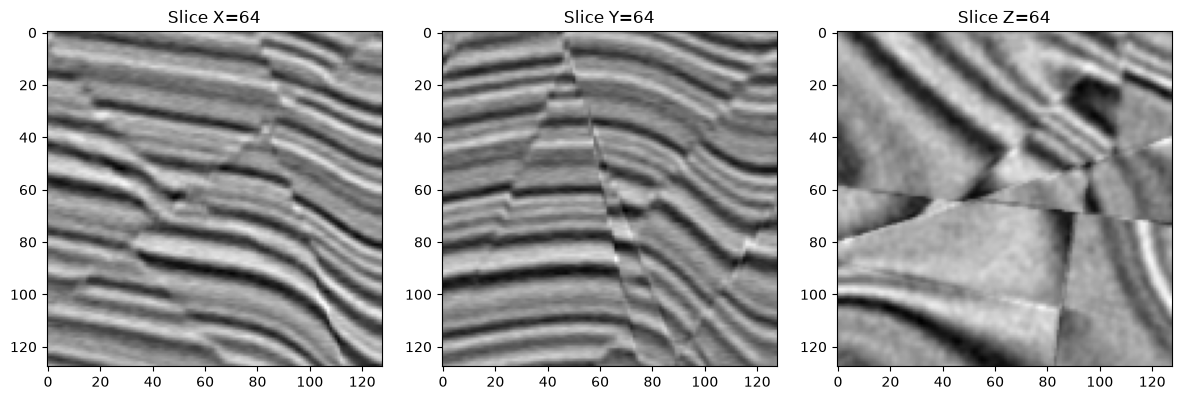

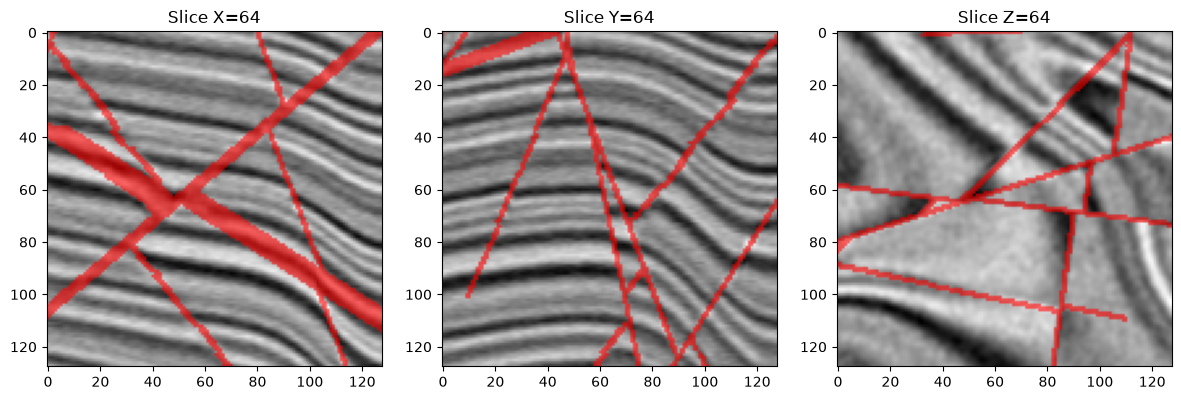



 showing index 1: img_0001.npy


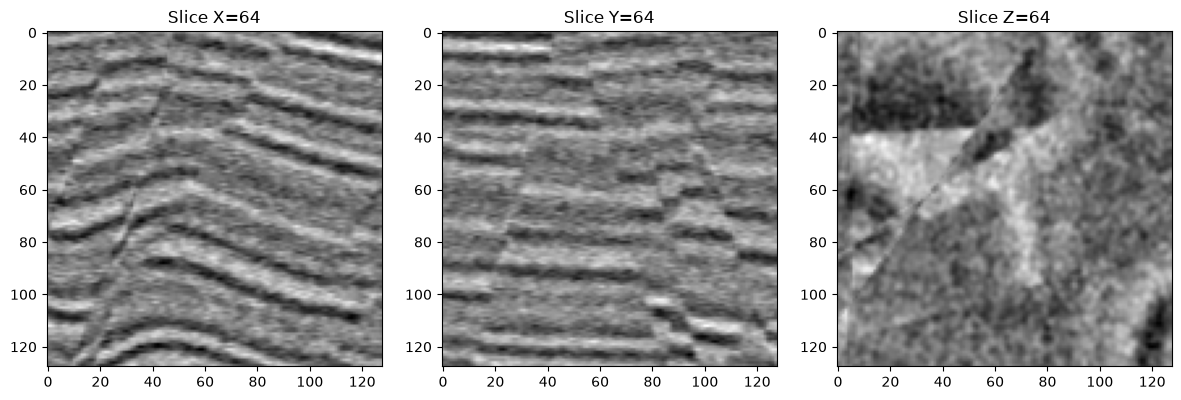

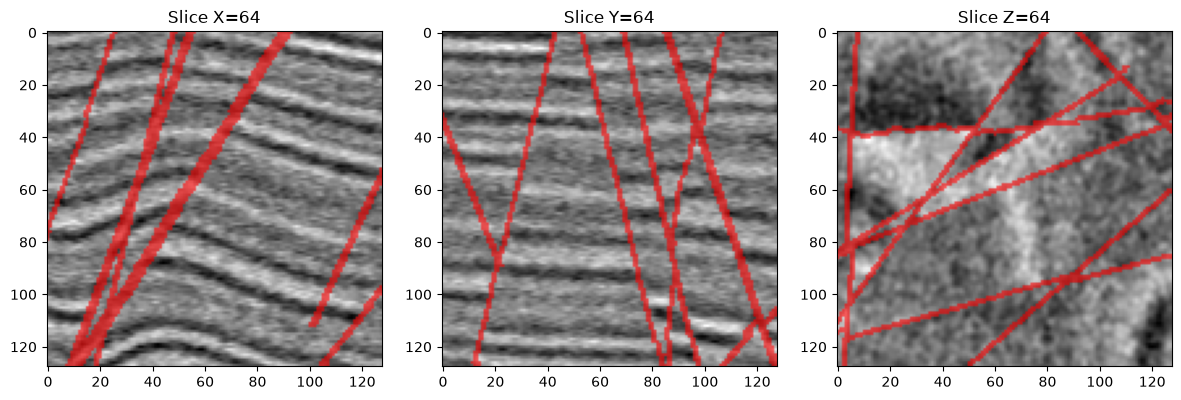



 showing index 2: img_0002.npy


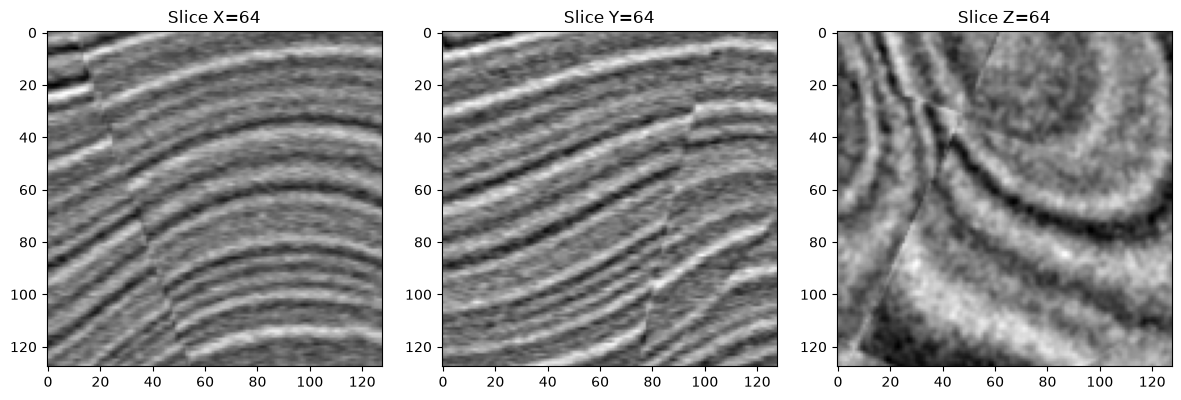

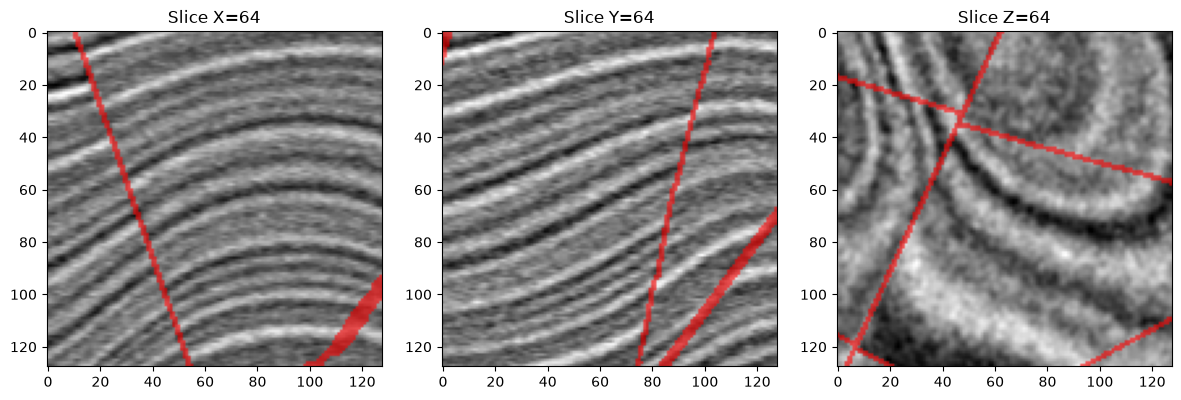



 showing index 3: img_0003.npy


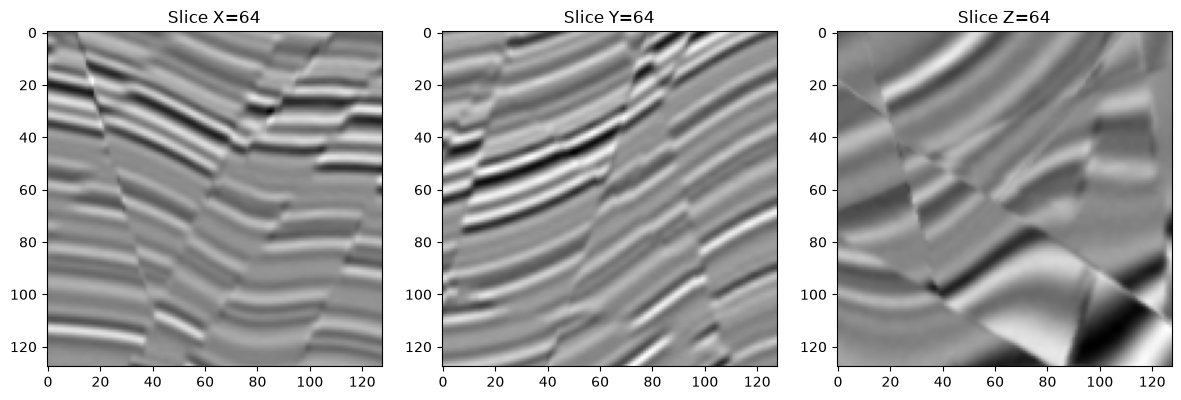

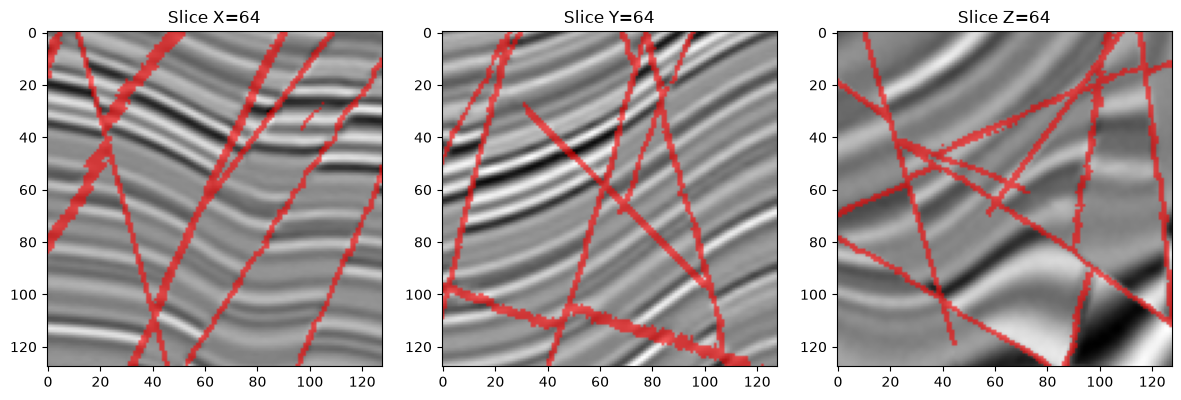



 showing index 4: img_0004.npy


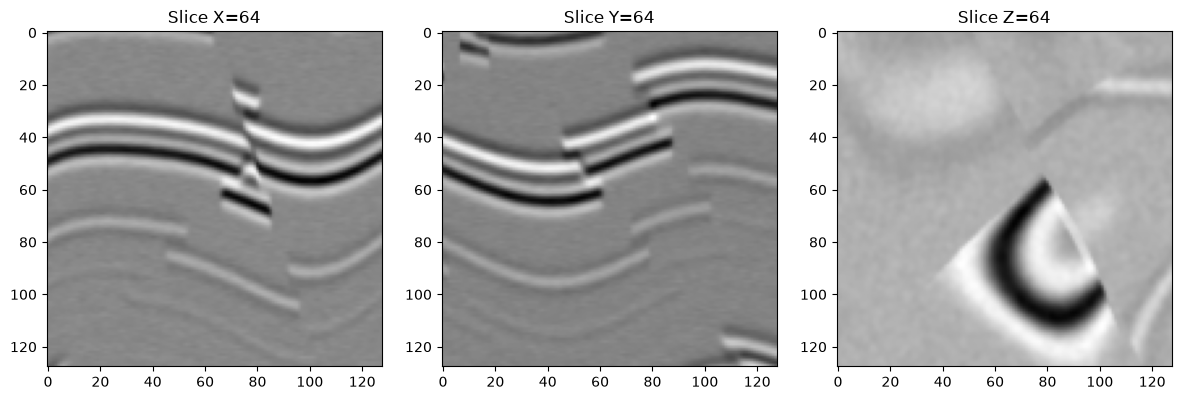

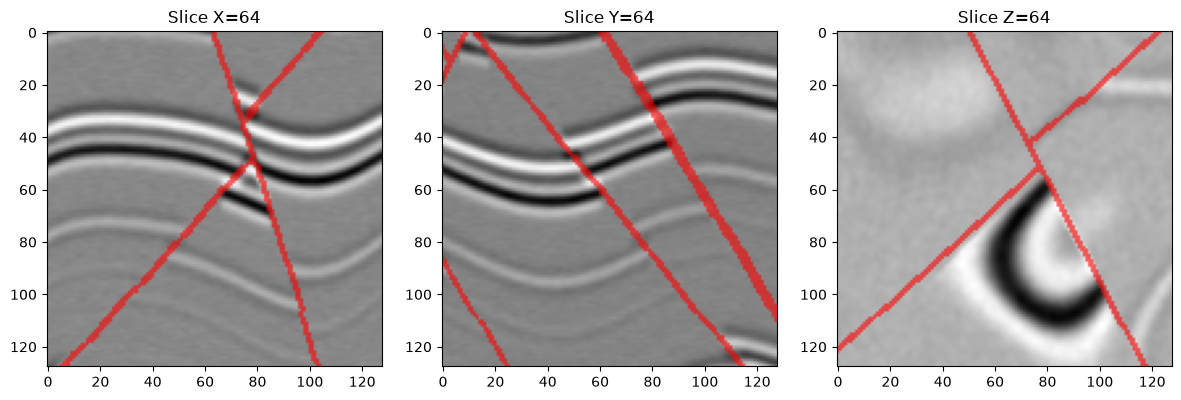

In [6]:
def getImage(base_path, file_name=None):
    path = os.path.join(base_path, file_name) if file_name else base_path
    return np.load(path)

for i, (img_path, msk_path) in enumerate(zip(images, masks)):
    if i == 5:
        break

    file_name = Path(img_path).name
    print(f'\n\n showing index {i}:', file_name)

    img  = getImage('original/images', file_name)
    mask = getImage('original/masks',  file_name)

    showTile(img=img)
    showTile(img=img, mask=mask)

### NORMALIZAÇÃO

- `scaling` do `info.json` escolhe o escalonamento da `Normalization` (`Dataset/index.py`); sem a chave é `'normalize'`.
- `'normalize'`: min-max de cada volume para [0, 1].
- `'percentile'`: corte no p01/p99 do conjunto inteiro, reescalado para [0, 1].
- `'standardize'`: padronização de cada volume (média 0, desvio 1), o passo da seção 3.2 do artigo da ResACEUnet.
- `null`: o volume cru, sem escalonamento.
- A escolha vai para a coluna `scaling` do `DataBase.csv`; o `index.py` refaz o `Format` quando a rodada pede outro.

In [7]:
SCALING   = OPTIONS.get('scaling', Normalization.DEFAULT)
normalize = Normalization(SCALING).fit(images, getImage)

setFolder('images')
setFolder('masks')
print(normalize)

Normalization('normalize'): min-max de cada volume para [0, 1]


In [8]:
for img_path, msk_path in tqdm(zip(images, masks), total=len(images)):
    img = getImage('original/images', img_path)
    msk = getImage('original/masks',  msk_path)

    img = normalize(img)
    file_name = Path(img_path).name
    
    np.save(os.path.join('images', file_name), img)
    np.save(os.path.join('masks',  file_name),  msk)

100%|██████████| 220/220 [00:00<00:00, 241.75it/s]


In [9]:
df = [] 

for img_path, mask_path in tqdm(zip(getFiles('images'), getFiles('masks'))):
    img  = np.load(img_path)
    mask = np.load(mask_path)
    data = dict()

    data['id'] = Path(img_path).name
    data['img_min']  = np.min(img)
    data['img_max']  = np.max(img)
    data['img_mean'] = np.mean(img)
    data['img_std']  = np.std(img)

    data['msk_min'] = np.min(mask)
    data['msk_max'] = np.max(mask)

    data['shape'] = img.shape
    data['img_path']  = img_path
    data['mask_path'] = mask_path
    data['scaling'] = SCALING
    df.append(data)


df = pd.DataFrame(df)
print(df.img_path.iloc[2])
df

220it [00:00, 360.35it/s]


/home/lamcegrva/Projects/Falhas/Dataset/dataset_74/images/img_0002.npy


,id,img_min,img_max,img_mean,img_std,msk_min,msk_max,shape,img_path,mask_path,scaling
0,img_0000.npy,0.0,1.0,0.529913,0.146943,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
1,img_0001.npy,0.0,1.0,0.503019,0.121774,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
2,img_0002.npy,0.0,1.0,0.469683,0.116922,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
3,img_0003.npy,0.0,1.0,0.524412,0.117401,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
4,img_0004.npy,0.0,1.0,0.524728,0.098068,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
...,...,...,...,...,...,...,...,...,...,...,...
215,img_0215.npy,0.0,1.0,0.521569,0.150795,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
216,img_0216.npy,0.0,1.0,0.470715,0.132741,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
217,img_0217.npy,0.0,1.0,0.505539,0.117533,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
218,img_0218.npy,0.0,1.0,0.469617,0.101798,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize


In [ ]:
pd.concat([getDataInfo(images, getImage, 'original'), getDataInfo(getFiles('images'), np.load, 'formatado')])

,arquivos,formato,shape,min,max,media,desvio
original,220,.npy float32,"(128, 128, 128)",-6.322393,6.709175,1.550716e-12,1.000000
formatado,220,.npy float32,"(128, 128, 128)",0.000000,1.000000,4.993075e-01,0.129439


In [10]:
if OPTIONS.get('img_size') is None:
    df.to_csv('DataBase.csv', index=None)
    display(df)
    sys.exit("Finalizando o programa: sem tiles nessa rodada")

,id,img_min,img_max,img_mean,img_std,msk_min,msk_max,shape,img_path,mask_path,scaling
0,img_0000.npy,0.0,1.0,0.529913,0.146943,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
1,img_0001.npy,0.0,1.0,0.503019,0.121774,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
2,img_0002.npy,0.0,1.0,0.469683,0.116922,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
3,img_0003.npy,0.0,1.0,0.524412,0.117401,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
4,img_0004.npy,0.0,1.0,0.524728,0.098068,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
...,...,...,...,...,...,...,...,...,...,...,...
215,img_0215.npy,0.0,1.0,0.521569,0.150795,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
216,img_0216.npy,0.0,1.0,0.470715,0.132741,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
217,img_0217.npy,0.0,1.0,0.505539,0.117533,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize
218,img_0218.npy,0.0,1.0,0.469617,0.101798,0,1,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,normalize


SystemExit: Finalizando o programa: sem tiles nessa rodada

/home/lamcegrva/miniconda3/envs/torch-gpu/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


# TILES

In [ ]:
IMG_SIZE = tuple(OPTIONS['img_size'])
IMG_SIZE

In [ ]:
# os tiles saem de images/ e masks/ (ja normalizados e com os eixos corrigidos), nao dos .dat originais
tileImages = getFiles('images')
tileMasks  = getFiles('masks')

tiles = TilesBuilder(target_size=IMG_SIZE, main_dir='tiles')
for img_path, mask_path in tqdm(zip(tileImages, tileMasks), total=len(tileImages)):
    tiles.update(img_path,  'images/', is_mask=False)
    tiles.update(mask_path, 'masks/',  is_mask=True)

In [ ]:
print(len(getFiles('tiles/images')), 'imagens geradas')

In [ ]:
df = pd.DataFrame()
df['img_path']  = getFiles('tiles/images')
df['mask_path'] = getFiles('tiles/masks')

assert len(df) > 0, 'nenhum tile foi gerado'
assert [Path(p).stem for p in df.img_path] == [Path(p).stem for p in df.mask_path], 'tiles de imagem e mascara desalinhados'

stats = []
for path in tqdm(df.img_path, total=len(df)):
    tile = np.load(path)
    stats.append({
        'shape': tile.shape,
        'min':   np.min(tile),
        'max':   np.max(tile),
        'mean':  np.mean(tile),
        'std':   np.std(tile),
    })

for column in ['shape', 'min', 'max', 'mean', 'std']:
    df[column] = [item[column] for item in stats]

shapes = set(df['shape'])
assert shapes == {IMG_SIZE}, f'tiles com shape inesperado: {shapes} (esperado {IMG_SIZE})'

df['scaling'] = SCALING
print(df.img_path.iloc[0])
df.to_csv('DataBase.csv', index=None)
df